## **Messwerte**

In [139]:
import numpy as np
import uncertainties as uc
import uncertainties.unumpy as unp


R_V_data = 100 #Vorwiderstand in Ohm
R_V_Fehler = 1
R_V = uc.ufloat(R_V_data, R_V_Fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

f_data = np.array([0.1, 0.25, 0.5, 0.75, 1, 2.5, 5, 7.5, 9, 9.25, 9.5, 9.75, 10, 10.25, 10.5, 10.75, 11, 25, 50, 75, 100]) *10**3 #gemessene Frequenzen in Hz
f_fehler = 1
f = unp.uarray(f_data, f_fehler)
omega = f * 2* np.pi

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

U_RV_data = np.array([21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1]) #Spannung am Vorwiederstand in V
U_RV_Fehler = 1
U_RV = unp.uarray(U_RV_data, U_RV_data)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

U_RLC_data = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]) #Spannung an der RLC Masche in V
U_RLC_fehler = 1
U_RLC = unp.uarray(U_RLC_data, U_RLC_fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

deltaT_data = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1]) #Zeitliche Verschiebung der Spannungen in s
deltaT_Fehler = 0.1
deltaT = unp.uarray(deltaT_data, deltaT_Fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

deltaPhi = omega * deltaT #Phasenverschiebung in rad


## **Plots und Regressionen für die Einzelbereiche**

Kapazität aus linearer Regression: C = (-6+/-7)e-07 F 

Induktivität aus linearer Regression: L = 0.0022+/-0.0027 H 

Berechnete Resonanzfrequenz: omega_res = 21+/-14 1/s 

Wiederstand aus Minimum des Fits: R = 71.08000660210382 Ohm 

Wiederstand aus Wert des Fits bei berechnetem omega_Res: R = 3742.0+/-1.8 Ohm 



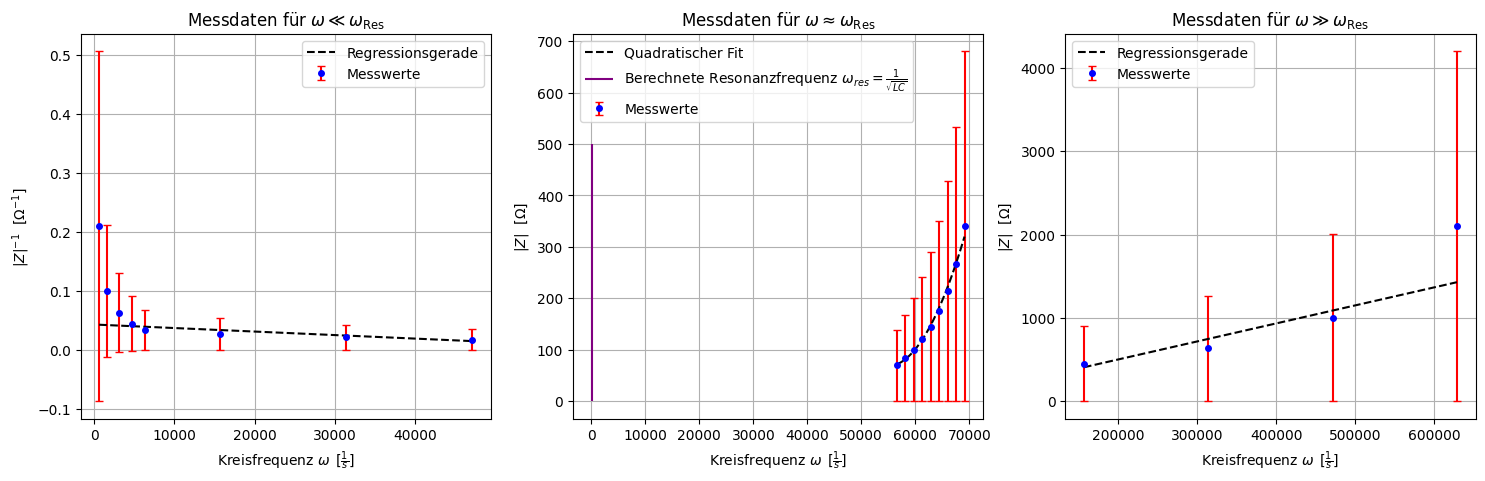

In [140]:
import scipy
import matplotlib.pyplot as plt

#Bereiche
index_smallerRes = slice(0,8)
index_Res = slice(8, 17)
index_higherRes = slice(17, 21)

#Berechnung der Impedanzen

Z = R_V * (U_RLC / U_RV) #Betrag der Impedanz in Ohm

fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (18,5))

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
# Auswertung für omega << omega_res

def f(x, k, c):
    return k*x + c

Z_inv = 1/Z

coefficients1, pcov1 = scipy.optimize.curve_fit(f, unp.nominal_values(omega)[index_smallerRes], unp.nominal_values(Z_inv)[index_smallerRes], sigma= unp.std_devs(Z_inv)[index_smallerRes], absolute_sigma= True)

C = uc.ufloat(coefficients1[0], np.sqrt(pcov1[0,0]))
c1 = coefficients1[1]

print(f"Kapazität aus linearer Regression: C = {C} F \n")

ax1.errorbar(unp.nominal_values(omega)[index_smallerRes], unp.nominal_values(Z_inv)[index_smallerRes] , yerr= unp.std_devs(Z_inv)[index_smallerRes] , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

ax1.plot(unp.nominal_values(omega)[index_smallerRes], f(unp.nominal_values(omega)[index_smallerRes], coefficients1[0],coefficients1[1] ), label = "Regressionsgerade", color = "black", linestyle = "--")

ax1.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax1.set_ylabel("$|Z|^{-1}$  $[\\Omega ^{-1}]$")
ax1.grid(True)
ax1.set_title("Messdaten für $\\omega \\ll \\omega _{\\mathrm{Res}}$")
ax1.legend()


"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
# Auswertung für omega >> omega_res

coefficients2, pcov2 = scipy.optimize.curve_fit(f, unp.nominal_values(omega)[index_higherRes], unp.nominal_values(Z)[index_higherRes], sigma= unp.std_devs(Z)[index_higherRes], absolute_sigma= True)

L = uc.ufloat(coefficients2[0], np.sqrt(pcov2[0,0]))
c2 = coefficients2[1]

print(f"Induktivität aus linearer Regression: L = {L} H \n")

ax3.errorbar(unp.nominal_values(omega)[index_higherRes], unp.nominal_values(Z)[index_higherRes] , yerr= unp.std_devs(Z)[index_higherRes] , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

ax3.plot(unp.nominal_values(omega)[index_higherRes], f(unp.nominal_values(omega)[index_higherRes], coefficients2[0],coefficients2[1] ), label = "Regressionsgerade", color = "black", linestyle = "--")

ax3.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax3.set_ylabel("$|Z|$  $[\\Omega ]$")
ax3.grid(True)
ax3.set_title("Messdaten für $\\omega \\gg \\omega _{\\mathrm{Res}}$")
ax3.legend()


"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
# Auswertung für omega ~ omega_res

def quad(x, a, b, c):
    return a*(x**2) + b*x +c

coefficients3, pcov3 = scipy.optimize.curve_fit(quad, unp.nominal_values(omega)[index_Res], unp.nominal_values(Z)[index_Res], sigma= unp.std_devs(Z)[index_Res], absolute_sigma= True)

ax2.errorbar(unp.nominal_values(omega)[index_Res], unp.nominal_values(Z)[index_Res], yerr= unp.std_devs(Z)[index_Res] , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(np.min(unp.nominal_values(omega)[index_Res]), np.max(unp.nominal_values(omega)[index_Res]))
ax2.plot(xwerte, quad(xwerte, coefficients3[0],coefficients3[1], coefficients3[2]), label = "Quadratischer Fit", color = "black", linestyle = "--")

C = 1 #TODO Chane the Temporary assignement (its there so the Code will run with the Dummy values)
omega_res_calc = 1 / unp.sqrt(L*C)
print(f"Berechnete Resonanzfrequenz: omega_res = {omega_res_calc} 1/s \n")

ax2.vlines(omega_res_calc.nominal_value, ymin = 0, ymax = 500, color = "purple", label = "Berechnete Resonanzfrequenz $\\omega _{res} = \\frac{1}{\\sqrt{LC}}$")

R = np.min(quad(xwerte, coefficients3[0],coefficients3[1], coefficients3[2]))
print(f"Wiederstand aus Minimum des Fits: R = {R} Ohm \n")

R_calc = quad(omega_res_calc, coefficients3[0],coefficients3[1], coefficients3[2])
print(f"Wiederstand aus Wert des Fits bei berechnetem omega_Res: R = {R_calc} Ohm \n")

ax2.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax2.set_ylabel("$|Z|$  $[\\Omega ]$")
ax2.grid(True)
ax2.set_title("Messdaten für $\\omega \\approx \\omega _{\\mathrm{Res}}$")
ax2.legend()

## **Plot des gesamten Frequenzbereichs**

In [141]:
#TODO

## **Plots der Phasenverschiebung**

In [142]:
#TODO